In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load HR Attrition Dataset

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

# Display first 5 rows
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (1470, 35)

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   ob

In [4]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [5]:
# Check duplicate records

print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
0


In [6]:
# Employee attrition count

print("Attrition Count:")
print(df['Attrition'].value_counts())

# Calculate attrition rate

attrition_rate = (df['Attrition'].value_counts()['Yes'] / len(df)) * 100

print("\nOverall Attrition Rate:", round(attrition_rate, 2), "%")

Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Overall Attrition Rate: 16.12 %


In [7]:
# Department-wise attrition count

department_attrition = pd.crosstab(
    df['Department'],
    df['Attrition']
)

print(department_attrition)

Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  828  133
Sales                   354   92


In [8]:
# Calculate attrition percentage by department

department_rate = (
    df.groupby('Department')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\nDepartment-wise Attrition Rate:")
print(department_rate.round(2))


Department-wise Attrition Rate:
Department
Human Resources           19.05
Research & Development    13.84
Sales                     20.63
Name: Attrition, dtype: float64


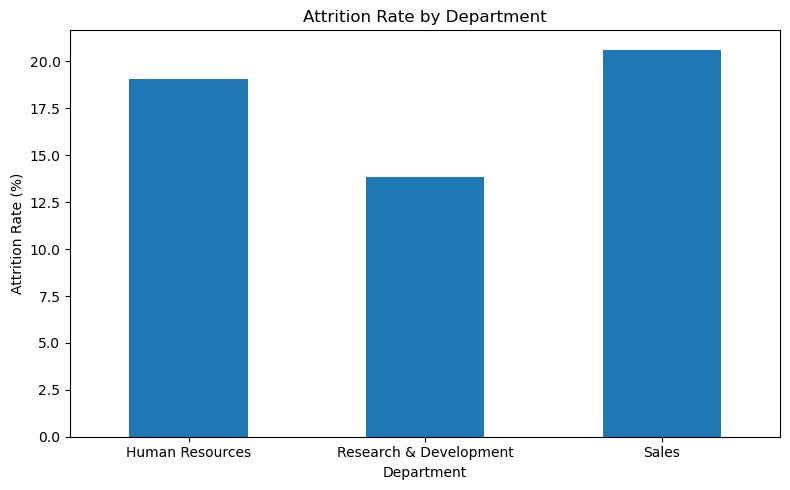

In [9]:
plt.figure(figsize=(8, 5))

department_rate.plot(kind='bar')

plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
# Job role-wise attrition count

jobrole_attrition = pd.crosstab(
    df['JobRole'],
    df['Attrition']
)

print(jobrole_attrition)

Attrition                   No  Yes
JobRole                            
Healthcare Representative  122    9
Human Resources             40   12
Laboratory Technician      197   62
Manager                     97    5
Manufacturing Director     135   10
Research Director           78    2
Research Scientist         245   47
Sales Executive            269   57
Sales Representative        50   33


In [11]:
# Calculate attrition rate by job role

jobrole_rate = (
    df.groupby('JobRole')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\nJob Role-wise Attrition Rate:")
print(jobrole_rate.round(2).sort_values(ascending=False))


Job Role-wise Attrition Rate:
JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: Attrition, dtype: float64


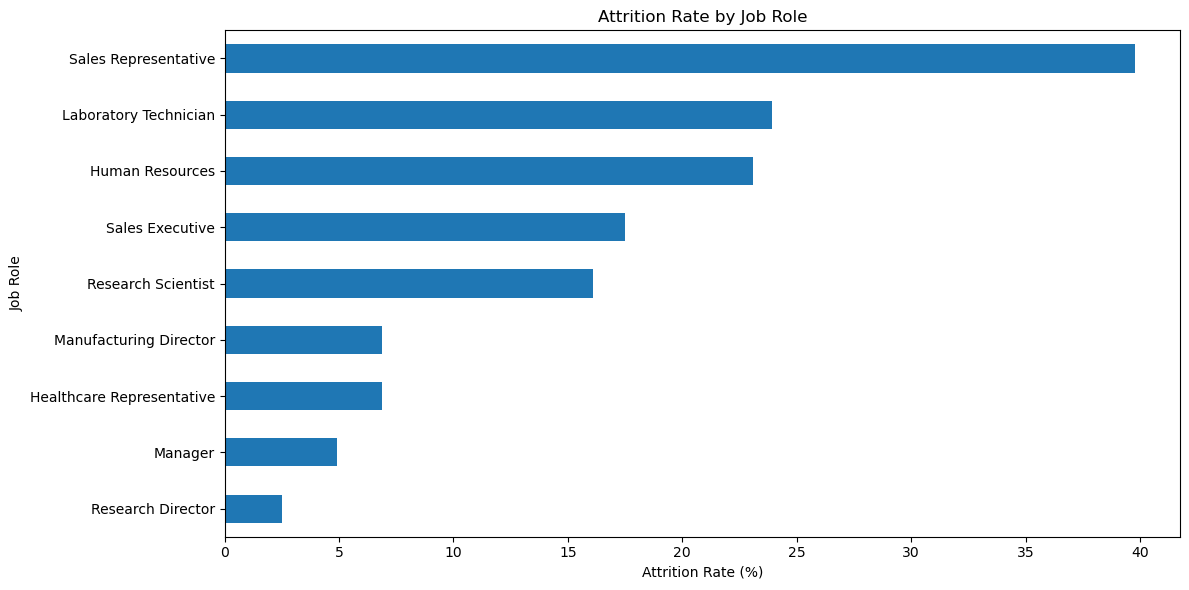

In [12]:
plt.figure(figsize=(12, 6))

jobrole_rate.sort_values().plot(kind='barh')

plt.title('Attrition Rate by Job Role')
plt.xlabel('Attrition Rate (%)')
plt.ylabel('Job Role')

plt.tight_layout()
plt.show()

In [13]:
# Create age groups

df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 65],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65']
)

print(df[['Age', 'AgeGroup']].head(10))

   Age AgeGroup
0   41    36-45
1   49    46-55
2   37    36-45
3   33    26-35
4   27    26-35
5   32    26-35
6   59    56-65
7   30    26-35
8   38    36-45
9   36    36-45


In [14]:
# Age group attrition analysis

age_attrition = (
    df.groupby('AgeGroup', observed=False)['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("Attrition Rate by Age Group:")
print(age_attrition.round(2))

Attrition Rate by Age Group:
AgeGroup
18-25    35.77
26-35    19.14
36-45     9.19
46-55    11.50
56-65    17.02
Name: Attrition, dtype: float64


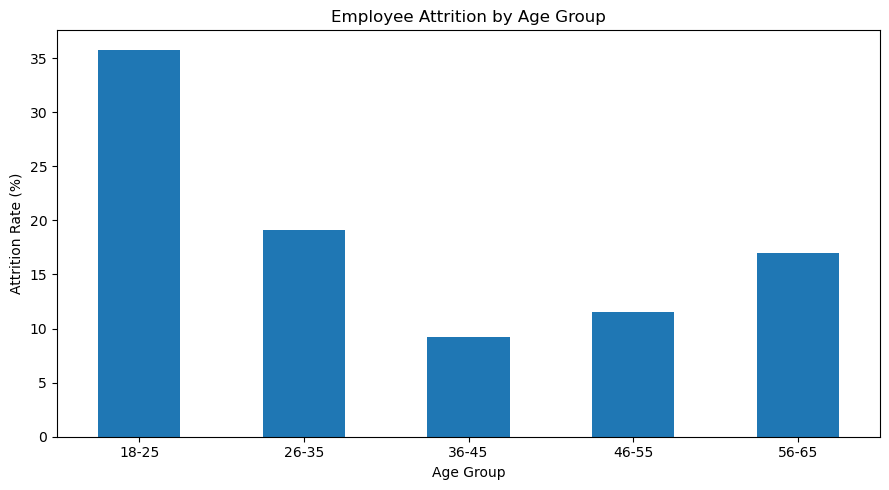

In [15]:
plt.figure(figsize=(9, 5))

age_attrition.plot(kind='bar')

plt.title('Employee Attrition by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [16]:
# Average monthly income by attrition

income_analysis = df.groupby('Attrition')['MonthlyIncome'].mean()

print("Average Monthly Income:")
print(income_analysis.round(2))

Average Monthly Income:
Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64


In [17]:
# Create income groups

df['IncomeGroup'] = pd.cut(
    df['MonthlyIncome'],
    bins=[0, 3000, 6000, 10000, 20000],
    labels=['Low Income', 'Medium Income', 'High Income', 'Very High Income']
)

print(df[['MonthlyIncome', 'IncomeGroup']].head(10))

   MonthlyIncome    IncomeGroup
0           5993  Medium Income
1           5130  Medium Income
2           2090     Low Income
3           2909     Low Income
4           3468  Medium Income
5           3068  Medium Income
6           2670     Low Income
7           2693     Low Income
8           9526    High Income
9           5237  Medium Income


In [18]:
# Income group attrition rate

income_attrition = (
    df.groupby('IncomeGroup', observed=False)['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\nAttrition Rate by Income Group:")
print(income_attrition.round(2))


Attrition Rate by Income Group:
IncomeGroup
Low Income          28.61
Medium Income       12.72
High Income         12.00
Very High Income     8.90
Name: Attrition, dtype: float64


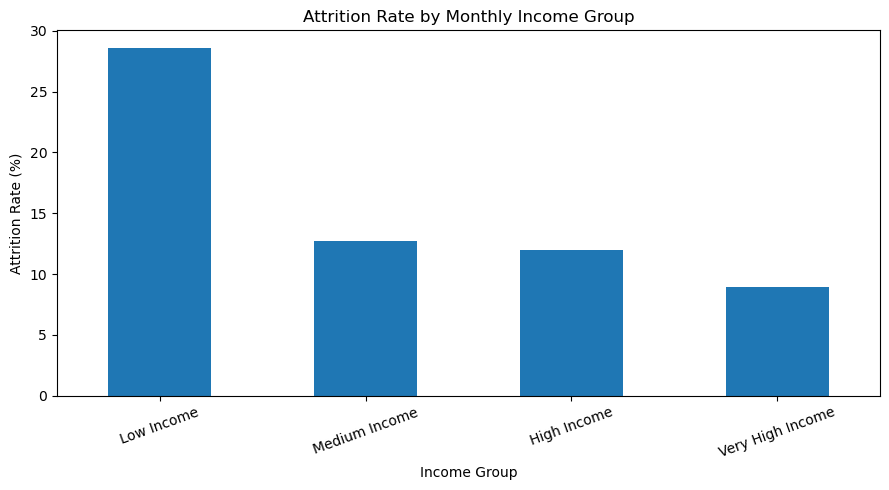

In [19]:
plt.figure(figsize=(9, 5))

income_attrition.plot(kind='bar')

plt.title('Attrition Rate by Monthly Income Group')
plt.xlabel('Income Group')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [20]:
# Job satisfaction vs attrition

satisfaction_analysis = pd.crosstab(
    df['JobSatisfaction'],
    df['Attrition']
)

print("Job Satisfaction Analysis:")
print(satisfaction_analysis)

Job Satisfaction Analysis:
Attrition         No  Yes
JobSatisfaction          
1                223   66
2                234   46
3                369   73
4                407   52


In [21]:
satisfaction_rate = (
    df.groupby('JobSatisfaction')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\nAttrition Rate by Job Satisfaction:")
print(satisfaction_rate.round(2))


Attrition Rate by Job Satisfaction:
JobSatisfaction
1    22.84
2    16.43
3    16.52
4    11.33
Name: Attrition, dtype: float64


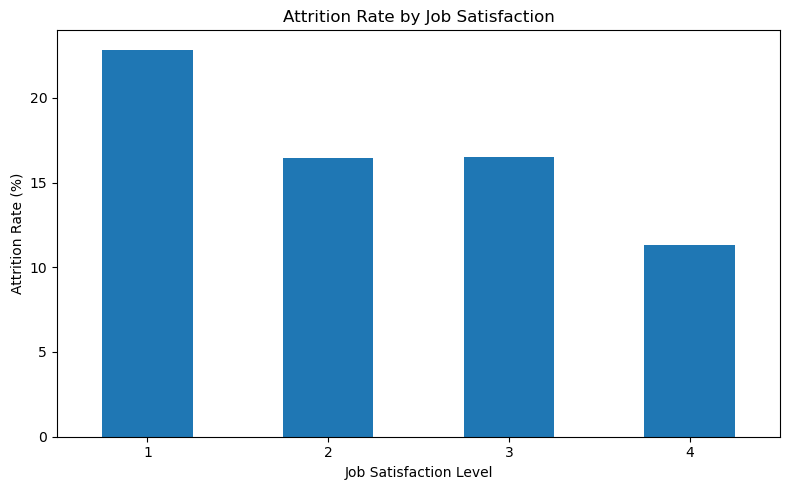

In [22]:
plt.figure(figsize=(8, 5))

satisfaction_rate.plot(kind='bar')

plt.title('Attrition Rate by Job Satisfaction')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [23]:
# Calculate average years at company

print("Average Years at Company by Attrition:")
print(df.groupby('Attrition')['YearsAtCompany'].mean().round(2))

Average Years at Company by Attrition:
Attrition
No     7.37
Yes    5.13
Name: YearsAtCompany, dtype: float64


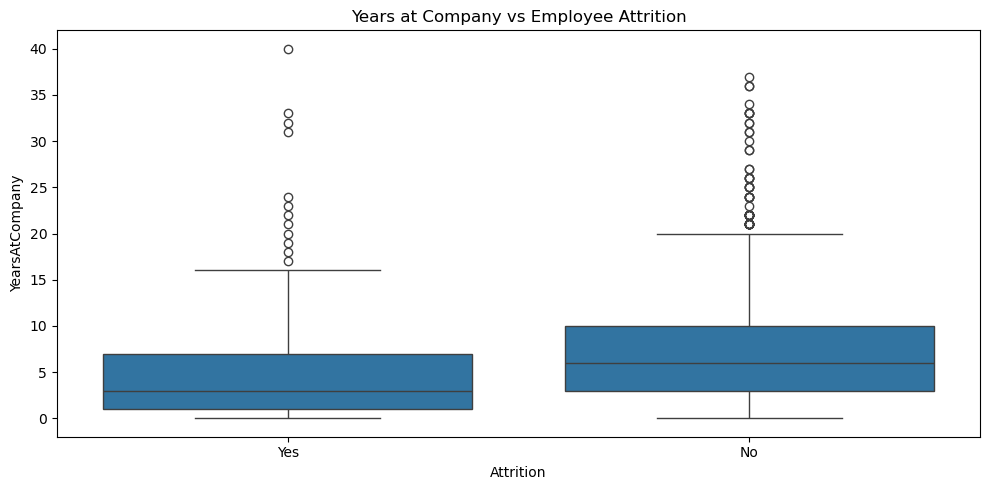

In [25]:
# Attrition by years at company

plt.figure(figsize=(10, 5))

sns.boxplot(
    x='Attrition',
    y='YearsAtCompany',
    data=df
)

plt.title('Years at Company vs Employee Attrition')
plt.tight_layout()
plt.show()

In [26]:
# Overtime vs Attrition

overtime_analysis = pd.crosstab(
    df['OverTime'],
    df['Attrition']
)

print("Overtime Analysis:")
print(overtime_analysis)

Overtime Analysis:
Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127


In [27]:
overtime_rate = (
    df.groupby('OverTime')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("\nAttrition Rate by Overtime:")
print(overtime_rate.round(2))


Attrition Rate by Overtime:
OverTime
No     10.44
Yes    30.53
Name: Attrition, dtype: float64


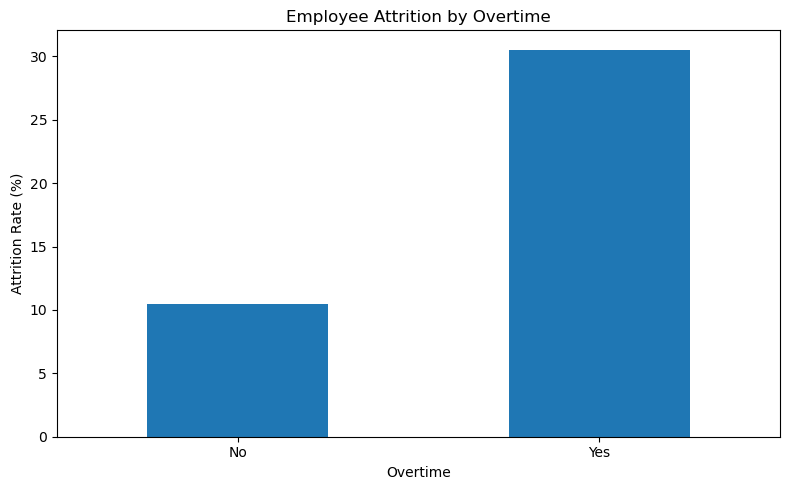

In [28]:
plt.figure(figsize=(8, 5))

overtime_rate.plot(kind='bar')

plt.title('Employee Attrition by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [29]:
# Gender-wise attrition

gender_rate = (
    df.groupby('Gender')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("Attrition Rate by Gender:")
print(gender_rate.round(2))

Attrition Rate by Gender:
Gender
Female    14.80
Male      17.01
Name: Attrition, dtype: float64


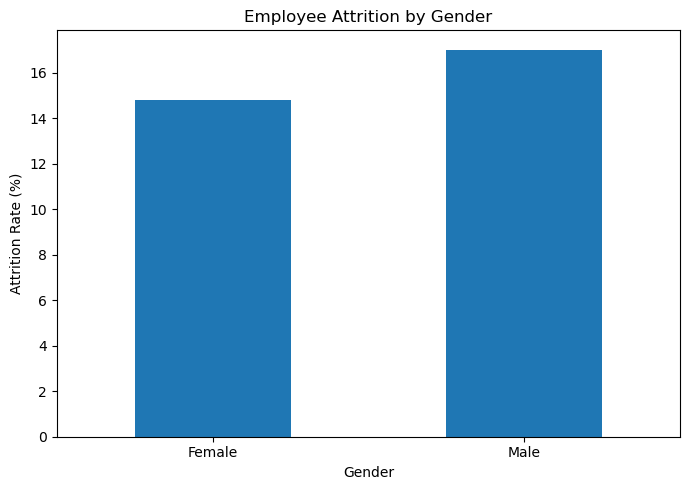

In [30]:
plt.figure(figsize=(7, 5))

gender_rate.plot(kind='bar')

plt.title('Employee Attrition by Gender')
plt.xlabel('Gender')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [31]:
# HR Attrition KPI Summary

total_employees = len(df)

employees_left = (df['Attrition'] == 'Yes').sum()

employees_stayed = (df['Attrition'] == 'No').sum()

attrition_rate = (employees_left / total_employees) * 100

average_age = df['Age'].mean()

average_income = df['MonthlyIncome'].mean()

average_tenure = df['YearsAtCompany'].mean()

print("========== HR ATTRITION KPI DASHBOARD ==========")

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print("Attrition Rate:", round(attrition_rate, 2), "%")
print("Average Employee Age:", round(average_age, 2))
print("Average Monthly Income:", round(average_income, 2))
print("Average Years at Company:", round(average_tenure, 2))

========== HR ATTRITION KPI DASHBOARD ==========
Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Attrition Rate: 16.12 %
Average Employee Age: 36.92
Average Monthly Income: 6502.93
Average Years at Company: 7.01


In [32]:
department_rate = (
    df.groupby('Department')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("Department with Highest Attrition:")
print(department_rate.idxmax())

print("Attrition Rate:")
print(round(department_rate.max(), 2), "%")

Department with Highest Attrition:
Sales
Attrition Rate:
20.63 %


In [33]:
# Overtime comparison

print("Overtime Attrition Comparison:")
print(
    df.groupby('OverTime')['Attrition']
    .apply(lambda x: round((x == 'Yes').mean() * 100, 2))
)

Overtime Attrition Comparison:
OverTime
No     10.44
Yes    30.53
Name: Attrition, dtype: float64


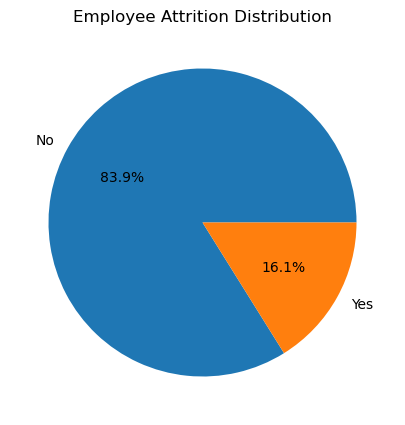

In [34]:
plt.figure(figsize=(7, 5))

df['Attrition'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    labels=['No', 'Yes']
)

plt.title('Employee Attrition Distribution')
plt.ylabel('')
plt.show()

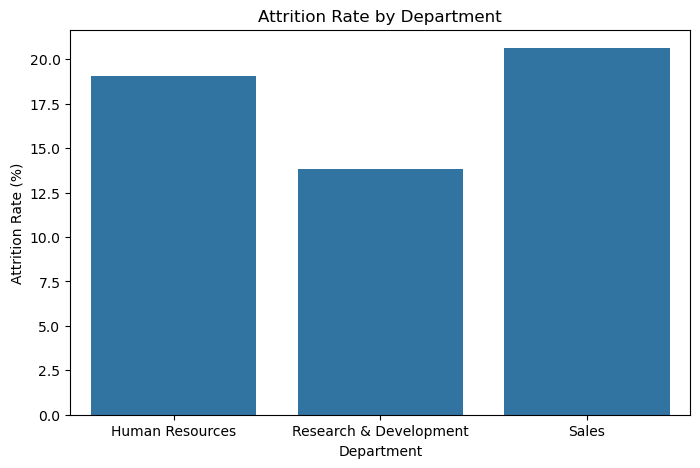

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=department_rate.index,
    y=department_rate.values
)

plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')
plt.show()

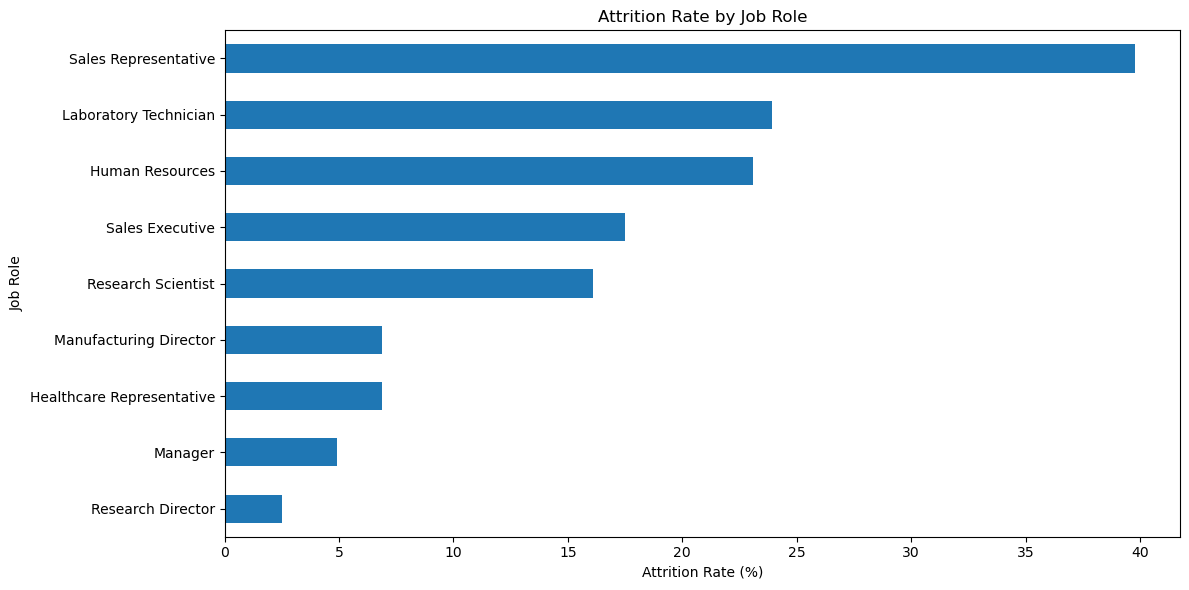

In [36]:
plt.figure(figsize=(12, 6))

jobrole_rate.sort_values().plot(kind='barh')

plt.title('Attrition Rate by Job Role')
plt.xlabel('Attrition Rate (%)')
plt.ylabel('Job Role')
plt.tight_layout()
plt.show()

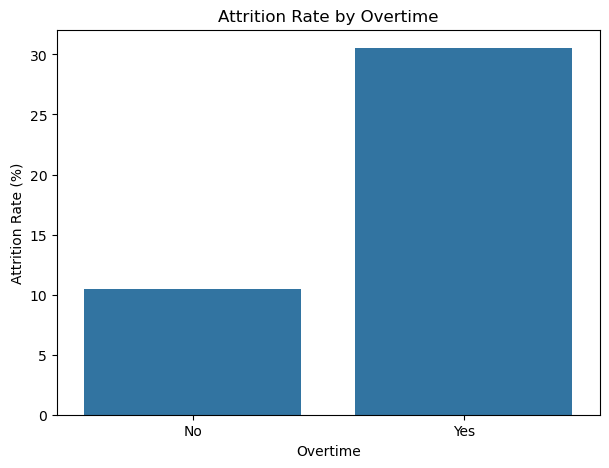

In [37]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=overtime_rate.index,
    y=overtime_rate.values
)

plt.title('Attrition Rate by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Attrition Rate (%)')
plt.show()

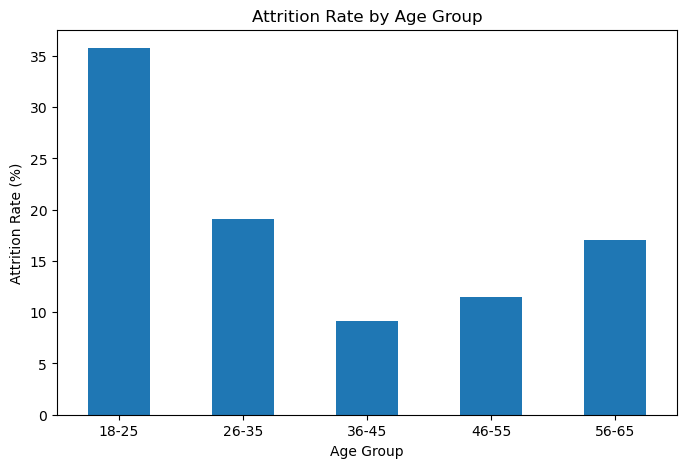

In [38]:
plt.figure(figsize=(8, 5))

age_attrition.plot(kind='bar')

plt.title('Attrition Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()